<a href="https://colab.research.google.com/github/balon14/test/blob/main/test3_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Импорт библиотек и загрузка датасета

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# для загрузки файлов в Colab
from google.colab import files

In [15]:
uploaded = files.upload()

Saving export_sint.xlsx to export_sint (1).xlsx
Saving import_sint.xlsx to import_sint (1).xlsx


In [16]:
export_df = pd.read_excel('export_sint.xlsx')
import_df = pd.read_excel('import_sint.xlsx')

In [17]:
# Объединяем таблицы

exp = export_df.set_index("Страна").add_prefix("E_")
imp = import_df.set_index("Страна").add_prefix("I_")

# outer join — берём все страны из обоих файлов
data = exp.join(imp, how="outer").fillna(0)

print("\nОбъединённая таблица:")
print("Страны:", list(data.index))
print("Признаков:", data.shape[1])
print(data.round(1))

countries = data.index.tolist()
X = data.values
features = data.columns.tolist()


Объединённая таблица:
Страны: ['Бразилия', 'Германия', 'Индия', 'Казахстан', 'Китай', 'Латвия', 'Литва', 'Нидерланды', 'Польша', 'Россия', 'Турция', 'Украина']
Признаков: 23
            E_Лесоматериалы  E_Плиты ДСП  E_Чёрные металлы  E_Молоко и сливки  \
Страна                                                                          
Бразилия                0.0          0.0               0.0                0.0   
Германия                4.0          6.0              12.0                6.0   
Индия                   0.0          0.0               0.0                0.0   
Казахстан               8.0          6.0              18.0               12.0   
Китай                   2.0          2.0               8.0                2.0   
Латвия                 16.0         12.0               6.0               14.0   
Литва                  14.0         10.0               8.0               16.0   
Нидерланды              6.0          6.0               8.0               22.0   
Польша         

# Стандартизация

In [18]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Подбор числа классов

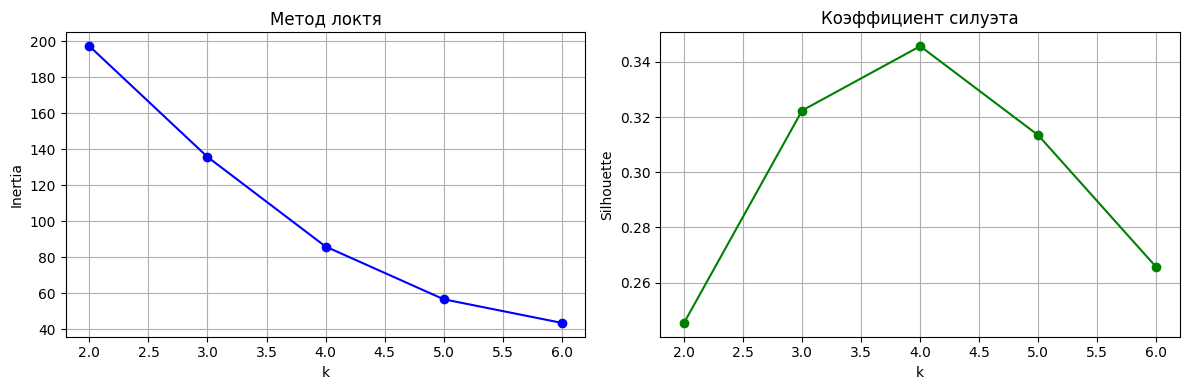


Лучший k по силуэту: 4


In [19]:
inertias = []
silhouettes = []
K_range = range(2, 7)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

# график
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(K_range), inertias, "bo-")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Метод локтя")
axes[0].grid(True)

axes[1].plot(list(K_range), silhouettes, "go-")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
axes[1].set_title("Коэффициент силуэта")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# выбираем k с лучшим силуэтом
best_k = list(K_range)[np.argmax(silhouettes)]
print(f"\nЛучший k по силуэту: {best_k}")

# Кластеризация

In [27]:
# K-Means
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X_scaled)
data["Кластер"] = km_labels

print("\n--- K-Means ---")
for cl in range(best_k):
    members = data[data["Кластер"] == cl].index.tolist()
    print(f"Кластер {cl}: {members}")

print(f"Silhouette: {silhouette_score(X_scaled, km_labels):.3f}")


# DBSCAN
print("\n--- 4.3. DBSCAN ---")
print("""
DBSCAN: основан на плотности. Не требует заранее задавать число кластеров,
может находить кластеры произвольной формы и выделять шум (outliers).
Параметры eps и min_samples подбираются эмпирически.
""")

# Подбор eps через k-distance (упрощённо)
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=3)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
distances = np.sort(distances[:, 2])
# Берём eps около 70-го перцентиля
eps_candidate = np.percentile(distances, 70)
print(f"Рекомендуемый eps (примерно): {eps_candidate:.2f}")

dbscan = DBSCAN(eps=eps_candidate, min_samples=2)
dbscan_labels = dbscan.fit_predict(X_scaled)
combined['Кластер_DBSCAN'] = dbscan_labels

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)
print(f"Найдено кластеров: {n_clusters_db}, шумовых точек: {n_noise}")
print("Распределение стран по кластерам DBSCAN:")
for cl in sorted(set(dbscan_labels)):
    members = combined[combined['Кластер_DBSCAN'] == cl].index.tolist()
    label_name = "Шум" if cl == -1 else f"Кластер {cl}"
    print(f"  {label_name}: {members}")

if n_clusters_db > 1:
    # Силуэт только для не-шумных точек
    mask = dbscan_labels != -1
    if mask.sum() > 1 and len(set(dbscan_labels[mask])) > 1:
        sil_db = silhouette_score(X_scaled[mask], dbscan_labels[mask])
        print(f"Silhouette score (DBSCAN, без шума): {sil_db:.3f}")
    else:
        sil_db = None
else:
    sil_db = None


--- K-Means ---
Кластер 0: ['Китай']
Кластер 1: ['Германия', 'Казахстан', 'Литва', 'Нидерланды', 'Польша', 'Россия']
Кластер 2: ['Бразилия', 'Индия', 'Турция']
Кластер 3: ['Латвия', 'Украина']
Silhouette: 0.346

--- Hierarchical ---
Кластер 0: ['Германия', 'Казахстан', 'Литва', 'Нидерланды', 'Польша', 'Россия']
Кластер 1: ['Бразилия', 'Индия', 'Турция']
Кластер 2: ['Латвия', 'Украина']
Кластер 3: ['Китай']
Silhouette: 0.346

--- 4.3. DBSCAN ---

DBSCAN: основан на плотности. Не требует заранее задавать число кластеров,
может находить кластеры произвольной формы и выделять шум (outliers).
Параметры eps и min_samples подбираются эмпирически.

Рекомендуемый eps (примерно): 5.23
Найдено кластеров: 3, шумовых точек: 1
Распределение стран по кластерам DBSCAN:
  Шум: ['Китай']
  Кластер 0: ['Бразилия', 'Индия', 'Турция']
  Кластер 1: ['Германия', 'Казахстан', 'Литва', 'Нидерланды', 'Польша', 'Россия']
  Кластер 2: ['Латвия', 'Украина']
Silhouette score (DBSCAN, без шума): 0.384


# Профили кластеров

In [21]:
print("\n" + "=" * 50)
print("ПРОФИЛИ КЛАСТЕРОВ (средние значения)")
print("=" * 50)

profile = data.groupby("Кластер")[features].mean()
print(profile.round(1).T)

# подробное описание
print("\n" + "=" * 50)
print("Описание кластеров")
print("=" * 50)

overall_mean = data[features].mean()

for cl in range(best_k):
    members = data[data["Кластер"] == cl].index.tolist()
    print(f"\nКластер {cl}: {', '.join(members)}")

    cl_mean = profile.loc[cl]
    diff = cl_mean - overall_mean

    # топ признаков выше среднего
    top_high = diff.nlargest(5)
    print("  Сильные стороны (выше среднего):")
    for feat, val in top_high.items():
        if val > 1:
            name = feat[2:] if feat.startswith(("E_", "I_")) else feat
            direction = "экспорт" if feat.startswith("E_") else "импорт"
            print(f"    - {name} ({direction}): {cl_mean[feat]:.1f}")


ПРОФИЛИ КЛАСТЕРОВ (средние значения)
Кластер                     0     1     2     3
E_Лесоматериалы           2.0  10.0   0.0  11.0
E_Плиты ДСП               2.0   9.0   0.0   8.0
E_Чёрные металлы          8.0  13.0   0.0  15.0
E_Молоко и сливки         2.0  13.3   0.0  12.0
E_Сыры и творог           2.0  10.3   0.0   9.0
E_Мясо птицы              2.0   5.3   0.0   5.0
E_Говядина                1.0   3.0   0.0   3.0
E_Сахар                   2.0   7.0   0.0   8.5
E_Мебель                 52.0  19.5   0.0  19.0
E_Лекарства              27.0   9.5   0.0   9.5
I_Растительные масла      4.0   7.0   8.0   0.0
I_Соевый шрот             2.0   5.7  18.7   0.0
I_Лекарства               6.0   7.0   9.3   0.0
I_Каучук                  4.0   5.3   5.3   0.0
I_Чёрные металлы          8.0  12.0   8.7   0.0
I_Трубы                   4.0   8.3   4.7   0.0
I_Металлоконструкции      4.0   6.7   3.3   0.0
I_Двигатели               4.0   7.0   3.3   0.0
I_Вычислительные машины  28.0   3.7   2.7   0.0
I_

# Визуализация


PCA: PC1 = 31.6%, PC2 = 23.1%


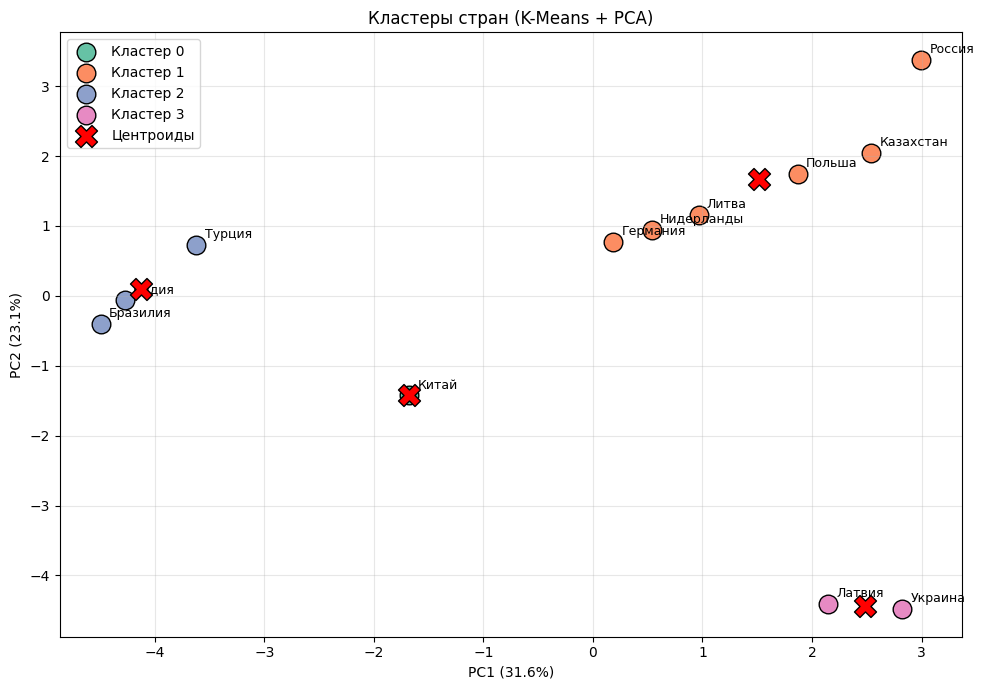

In [22]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"\nPCA: PC1 = {pca.explained_variance_ratio_[0]:.1%}, "
      f"PC2 = {pca.explained_variance_ratio_[1]:.1%}")

plt.figure(figsize=(10, 7))
colors = sns.color_palette("Set2", best_k)

for cl in range(best_k):
    mask = km_labels == cl
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=[colors[cl]], s=180, label=f"Кластер {cl}",
                edgecolors="black")

    # подписи стран
    for i, country in enumerate(countries):
        if mask[i]:
            plt.annotate(country, (X_pca[i, 0], X_pca[i, 1]),
                         xytext=(6, 5), textcoords="offset points",
                         fontsize=9)

# центроиды
centroids = pca.transform(kmeans.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],
            c="red", marker="X", s=250, label="Центроиды",
            edgecolors="black", zorder=5)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("Кластеры стран (K-Means + PCA)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Тепловая карта

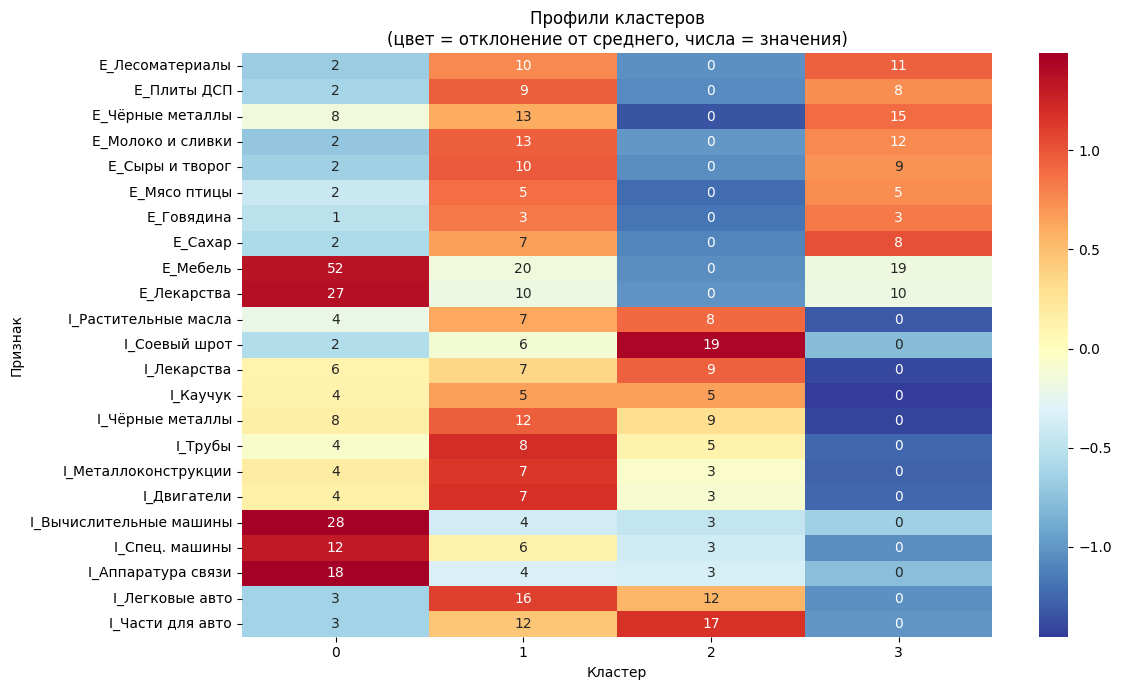

In [23]:
plt.figure(figsize=(12, 7))

# z-score для цвета, абсолютные значения для подписей
profile_z = (profile - profile.mean()) / profile.std()
sns.heatmap(profile_z.T, annot=profile.round(0).T, fmt=".0f",
            cmap="RdYlBu_r", center=0)
plt.title("Профили кластеров\n(цвет = отклонение от среднего, числа = значения)")
plt.ylabel("Признак")
plt.xlabel("Кластер")
plt.tight_layout()
plt.show()